# Hypothesis testing: z, t, errors, effect size and a first ANOVA — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D015_03_hypothesis_testing.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# Lesson 03 — Hypothesis Testing

> **Data:** `../data/tips.csv`, `../data/taxis.csv`, `../data/sleep.csv`, `../data/stack_overflow.feather` &nbsp;·&nbsp; **Time:** ~120 min &nbsp;·&nbsp; **Needs:** Lessons 01–02

## What you will be able to do

1. **State H₀ and H₁ properly**, and fix α *before* looking at the data.
2. **Explain Type I and Type II error** in the court-room framing, and say what choosing
   α = 0.05 actually buys and costs.
3. **Run a one-sample z-test by hand** — standard error, z, p — then with a library, and
   explain why the z-test is almost never usable on real data.
4. **Choose and run the right t-test**: one-sample, independent, or paired.
5. **Use Levene's test as the gate** between Student's t-test and Welch's.
6. **Run a one-way ANOVA** with Tukey or Games-Howell post hoc comparisons.
7. **Report an effect size next to every p-value**, and explain why a p-value alone is
   not a finding.

## The one idea to hold on to

A p-value answers one narrow question: *if there were truly no effect, how surprising
would this data be?* It does **not** tell you the effect is large, important, or real.
With enough rows, everything is significant — which is precisely the situation you will
be in for the rest of your career.

# Hypothesis Testing
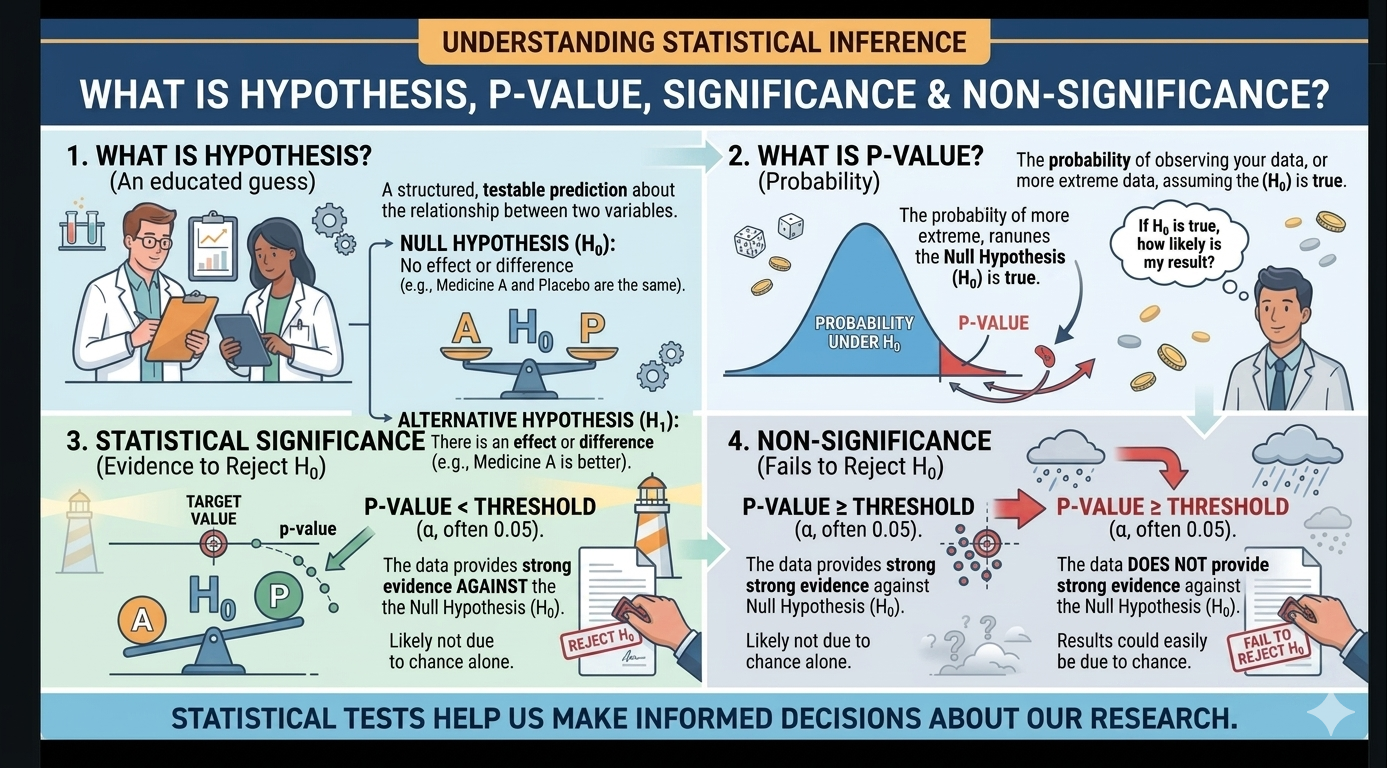

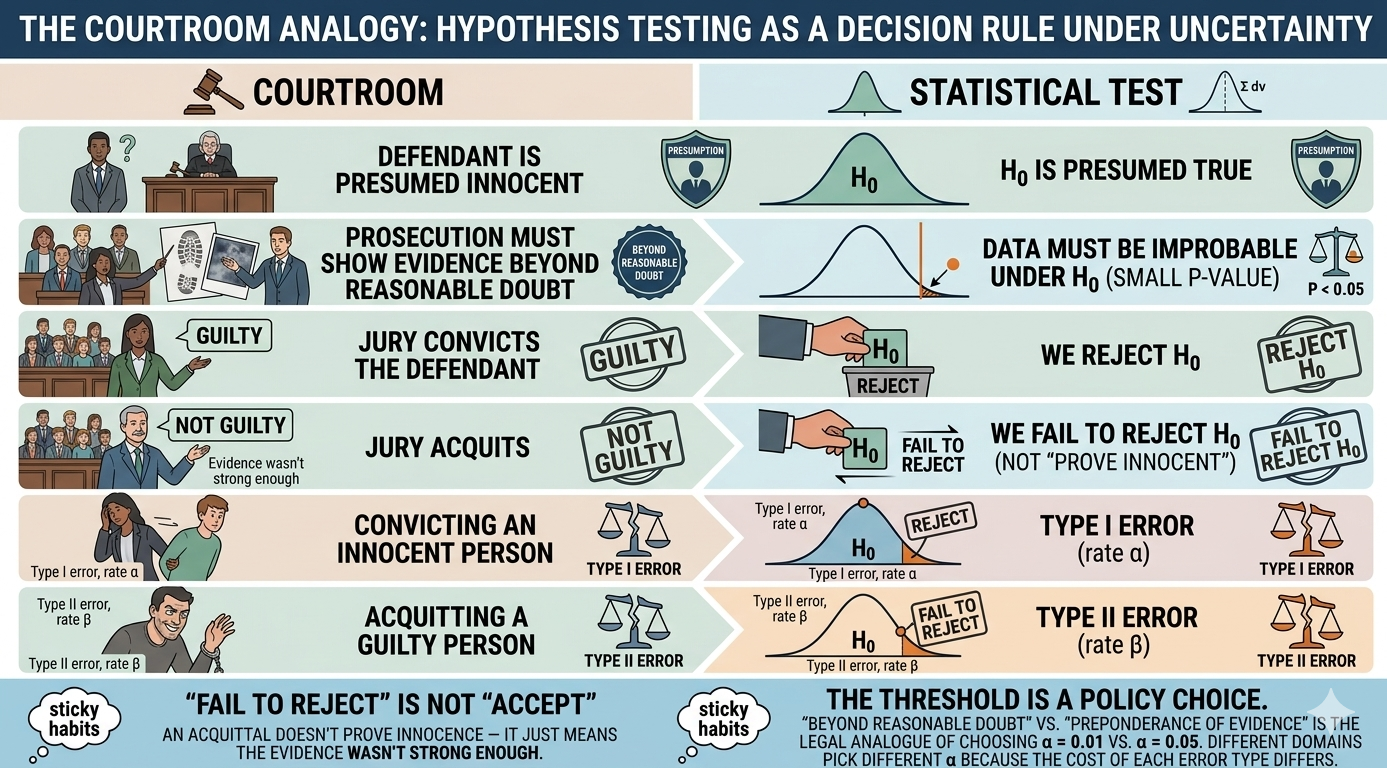

# Understanding the components in Hypothesis 
![two-sided.png](../FC_Lessons/two-sided.png)

### Summary of Hypothesis Testing Components

| Component | Technical Term | Layman's Explanation | My Graph's Value |
| :--- | :--- | :--- | :--- |
| **The Curve** | Null Hypothesis ($H_0$) | The "Normal" world where nothing interesting happened. | Black Bell Curve |
| **The Boundary** | Critical Value / Alpha ($\alpha$) | The line in the sand. If data crosses this, it's "too weird" to be a fluke. | $\pm 1.96$ (Red Zones) |
| **The Evidence** | Test Statistic ($z_{obs}$) | Your actual experimental result. Where does your data land? | $2.3$ (Orange Line) |
| **The Probability** | p-value | The % chance that your result happened by pure accident. | $0.0214$ (Blue Area) |
| **The Verdict** | Statistical Significance | Since the evidence crossed the line, we "Reject the Null." | Significant ($p < 0.05$) |

## Type 1 and Type 2 Error in Hypothesis Testing
![](https://scontent.fkul15-1.fna.fbcdn.net/v/t39.30808-6/509422662_1622930415213992_6906706627801167950_n.jpg?stp=dst-jpg_s1080x2048_tt6&_nc_cat=104&ccb=1-7&_nc_sid=7b2446&_nc_ohc=vAJSJCf1j74Q7kNvwGSSw8G&_nc_oc=Adph3-KcKJuSbpS8_ZzDp3_KK1JaBUv6_RNo-pWfyFUYjDTSAbzTjgGW5weqdzK3kXU&_nc_zt=23&_nc_ht=scontent.fkul15-1.fna&_nc_gid=bEvyhniUfYtlktLAJCQ5NA&_nc_ss=7a389&oh=00_Af1mS5wqn98WiUbFBjzVo8C_gk15PWRzf1TkU8zgUUX9Vg&oe=69E4CE13)


## Worked example — one-sample z-test by hand

**Scenario.** A factory claims its widgets weigh $\mu_0 = 5$ kg on average, with a known historical standard deviation $\sigma = 2$ kg. We sample $n = 50$ widgets from today's shift (drawn, for teaching purposes, from a **true** mean of $\mu = 5.2$). Is today's mean different from $5$?

- $H_0:\ \mu = 5$
- $H_1:\ \mu \neq 5$ (two-sided)
- $\alpha = 0.05$

Test statistic:

$$ Z \;=\; \frac{\bar X - \mu_0}{\sigma / \sqrt{n}}. $$

In [1]:
import numpy as np 
from scipy import stats

In [ ]:
# TODO: call `np.random.seed`
# Hint: np.random.seed

In [ ]:
# TODO: write the code for this step
# Name your result: mu_true, mu_0, sigma, n

In [ ]:
# TODO: compute `sample`
# Hint: np.random.normal
# Name your result: sample

In [ ]:
# TODO: compute `xbar`
# Hint: sample.mean
# Name your result: xbar

In [ ]:
# TODO: compute `se`, `z`
# Hint: np.sqrt
# Name your result: se, z

In [7]:
z

np.float64(1.4317937937716423)

In [ ]:
# TODO: compute `p`
# Hint: stats.norm.sf
# Name your result: p

In [9]:
p

np.float64(0.15220284395515882)

In [10]:
if p <= alpha:
    print('Reject H0')
else:
    print('Fail to reject H0')

Fail to reject H0


In [11]:
from statsmodels.stats.weightstats import ztest

In [ ]:
# TODO: call `ztest`
# Hint: ztest

In [13]:
z_stat, p_val

(np.float64(1.5732143213600485), np.float64(0.11566920028819022))

In [14]:
if p_val <= alpha:
    print('Reject H0')
else:
    print('Fail to reject H0')

Fail to reject H0


In [ ]:
# TODO: run a one-sample t-test
# Hint: stats.ttest_1samp

In [16]:
t_stat, p_val_t

(np.float64(1.5732143213600485), np.float64(0.12210464335876509))

In [17]:
if p_val_t <= alpha:
    print('Reject H0')
else:
    print('Fail to reject H0')

Fail to reject H0


In [18]:
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
np.random.seed(42)

In [19]:
import pandas as pd
tips = pd.read_csv('../../00-data/tips.csv')

In [20]:
tips.isnull().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [21]:
tips.shape

(244, 7)

In [ ]:
# TODO: write the code for this step
# Name your result: sample

In [ ]:
# TODO: draw a `plt.subplots`
# Hint: plt.subplots, .boxplot(), .hist(), plt.tight_layout

In [ ]:
# TODO: run a Shapiro-Wilk normality test
# Hint: stats.shapiro

In [25]:
sw_stat, sw_p

(np.float64(0.8978110496018733), np.float64(8.200360128656242e-12))

In [26]:
sample.mean()

np.float64(2.99827868852459)

In [ ]:
# TODO: run a one-sample t-test, storing the result in `mu0`
# Hint: stats.ttest_1samp, res1.confidence_interval
# Name your result: mu0, res1, ci1

In [28]:
res1.statistic, res1.pvalue

(np.float64(5.625287009994554), np.float64(5.0799884596864904e-08))

In [29]:
dd0f = n-1

In [30]:
sample.shape

(244,)

In [31]:
# FIXED: was `2.82res1.df`
res1.df

np.int64(243)

In [32]:
ci1.low, ci1.high

(np.float64(2.8237993062818205), np.float64(3.172758070767359))

In [33]:
print(f"we are 95% confident that the true mean tip lies roughly in between ${ci1.low:.2f} and ${ci1.high:.2f}")

we are 95% confident that the true mean tip lies roughly in between $2.82 and $3.17


In [34]:
if res1.pvalue <= alpha:
    print('Reject H0')
else:
    print('Fail to reject H0')

Reject H0


In [35]:
lunch = tips.loc[tips['time']=='Lunch','tip']
dinner = tips.loc[tips['time']=='Dinner','tip']

In [ ]:
# TODO: draw a `plt.subplots`
# Hint: plt.subplots, .boxplot(), .hist(), plt.tight_layout

In [ ]:
# TODO: run a Shapiro-Wilk normality test, storing the result in `sw_lunch`
# Hint: stats.shapiro
# Name your result: sw_lunch, sw_dinner

In [38]:
sw_lunch.statistic,sw_lunch.pvalue

(np.float64(0.8686735246429054), np.float64(3.6282022141600215e-06))

In [39]:
sw_dinner.statistic,sw_dinner.pvalue

(np.float64(0.9009283406982189), np.float64(1.7842347690678544e-09))

In [ ]:
# TODO: run Levene's test
# Hint: stats.levene

In [ ]:
# TODO: run an independent t-test, storing the result in `res2`
# Hint: stats.ttest_ind, res2.confidence_interval
# Name your result: res2, ci2

In [42]:
res2.pvalue, res2.statistic, ci2.low,ci2.high

(np.float64(0.04126342245429952),
 np.float64(-2.0593266215069774),
 np.float64(-0.7341107983413303),
 np.float64(-0.015053640161341586))

In [43]:
if res2.pvalue <= alpha:
    print('Reject H0')
else:
    print('Fail to reject H0')

Reject H0


In [44]:
print(f"we are 95% confident that the average mean tip duing lunch and dinner lies roughly in between ${ci2.low:.2f} and ${ci2.high:.2f}")

we are 95% confident that the average mean tip duing lunch and dinner lies roughly in between $-0.73 and $-0.02


In [ ]:
# ═══ CHECKPOINT — "Unconfusing Hypothesis Testing" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
from scipy import stats
mu_true = 5.2
mu_0 = 5.0
sigma = 2.0
n = 50
alpha = 0.05
sample = np.random.normal(loc=mu_true, scale=sigma, size=n)
xbar = sample.mean()
se = sigma / np.sqrt(n)
z = (xbar - mu_0) / se
p = 2 * stats.norm.sf(abs(z))
from statsmodels.stats.weightstats import ztest
z_stat, p_val = ztest(sample, value=mu_0)
t_stat, p_val_t = stats.ttest_1samp(sample, popmean=mu_0)
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
import pandas as pd
tips = pd.read_csv('../../00-data/tips.csv')
sample = tips['tip']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sw_stat, sw_p = stats.shapiro(sample)
mu0 = 2.5
res1 = stats.ttest_1samp(sample, popmean=mu0)
ci1 = res1.confidence_interval()
dd0f = n - 1
lunch = tips.loc[tips['time'] == 'Lunch', 'tip']
dinner = tips.loc[tips['time'] == 'Dinner', 'tip']
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
sw_lunch = stats.shapiro(lunch)
sw_dinner = stats.shapiro(dinner)
res2 = stats.ttest_ind(lunch, dinner, equal_var=False)
ci2 = res2.confidence_interval()

print("Checkpoint restored. Ready for: Unconfusing Hypothesis Testing")

### Unconfusing Hypothesis Testing

In [45]:
sample_df = tips.sample(50,random_state=12)

In [46]:
# Defining new group for testing
sample_df.columns

Index(['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size'], dtype='object')

In [47]:
sample_df.sex.unique()

array(['Male', 'Female'], dtype=object)

In [48]:
group_a = sample_df[sample_df['sex']=='Male']['tip']
group_b = sample_df[sample_df['sex']=='Female']['tip']

In [ ]:
# TODO: run Levene's test
# Hint: stats.levene

In [50]:
if p_levene < alpha:
    print('Welch t-test')
else:
    print('Student t-test')

Student t-test


In [ ]:
# TODO: run a one-sample t-test on `tip`, storing the result in `r1`
# Hint: stats.ttest_1samp
# Name your result: r1

In [52]:
ci_r1 = r1.confidence_interval()

In [53]:
ci_r1.low,ci_r1.high

(np.float64(2.6763557758645753), np.float64(3.472844224135425))

In [54]:
r1.statistic,r1.pvalue

(np.float64(0.37643813420094346), np.float64(0.7082163434033907))

In [55]:
if r1.pvalue <= alpha:
    print('Reject H0')
else:
    print('Fail to reject H0')

Fail to reject H0


In [56]:
## sanity check the population tip for each gender
male_tip_avg = tips[tips['sex']=='Male']['tip'].mean()
female_tip_avg = tips[tips['sex']=='Female']['tip'].mean()
male_tip_avg,female_tip_avg

(np.float64(3.0896178343949043), np.float64(2.8334482758620685))

In [57]:
# tips['tip'].mean()

In [ ]:
# TODO: run an independent t-test, storing the result in `r2`
# Hint: stats.ttest_ind
# Name your result: r2

In [59]:
if r2.pvalue <= alpha:
    print('Reject H0')
else:
    print('Fail to reject H0')

Fail to reject H0


In [60]:
r2.statistic, r2.confidence_interval()

(np.float64(0.5319314439704974),
 ConfidenceInterval(low=np.float64(-0.6120399266551028), high=np.float64(1.0442304028455784)))

In [61]:
group_a.describe(), group_b.describe()

(count    35.000000
 mean      3.139429
 std       1.476847
 min       1.440000
 25%       2.000000
 50%       3.000000
 75%       3.880000
 max       7.580000
 Name: tip, dtype: float64,
 count    15.000000
 mean      2.923333
 std       1.241288
 min       1.000000
 25%       2.115000
 50%       3.000000
 75%       3.125000
 max       5.200000
 Name: tip, dtype: float64)

In [62]:
tips[tips['sex']=='Male']['tip'].describe()

count    157.000000
mean       3.089618
std        1.489102
min        1.000000
25%        2.000000
50%        3.000000
75%        3.760000
max       10.000000
Name: tip, dtype: float64

In [63]:
tips[tips['sex']=='Female']['tip'].describe()

count    87.000000
mean      2.833448
std       1.159495
min       1.000000
25%       2.000000
50%       2.750000
75%       3.500000
max       6.500000
Name: tip, dtype: float64

In [ ]:
# TODO: write the code for this step

In [ ]:
# TODO: compute `df`
# Hint: pd.read_csv, df.head
# Name your result: df

In [66]:
data = df[['fare','tip','distance','payment','pickup_borough']].dropna()

In [67]:
data['fare']

0        7.0
1        5.0
2        7.5
3       27.0
4        9.0
        ... 
6428     4.5
6429    58.0
6430    16.0
6431     6.0
6432    15.0
Name: fare, Length: 6364, dtype: float64

In [ ]:
# TODO: run a one-sample t-test on `fare`, storing the result in `r3`
# Hint: stats.ttest_1samp
# Name your result: r3

In [69]:
r3.pvalue

np.float64(2.3375079967629677e-42)

In [ ]:
# TODO: write the code for this step

In [71]:
sig_check(r3.pvalue)

0.00
0.05
Reject H0


In [72]:
data.columns

Index(['fare', 'tip', 'distance', 'payment', 'pickup_borough'], dtype='object')

In [73]:
data.payment.unique()

array(['credit card', 'cash'], dtype=object)

In [74]:
credit_tips =  data[data['payment']=='credit card']['tip']
cash_tips = data[data['payment']=='cash']['tip']

In [75]:
data.groupby('payment')['tip'].describe()

,count,mean,std,min,25%,50%,75%,max
payment,,,,,,,,
cash,1807.0,0.000000,0.000000,0.0,0.0,0.0,0.00,0.00
credit card,4557.0,2.764909,2.414252,0.0,1.5,2.2,3.26,23.19


In [ ]:
# TODO: run a Shapiro-Wilk normality test on `payment`, `tip`, storing the result in `resr`
# Hint: stats.shapiro
# Name your result: resr

In [ ]:
# TODO: run an independent t-test
# Hint: stats.ttest_ind

In [78]:
sig_check(p_val)

0.00
0.05
Reject H0


In [79]:
import pandas as pd

In [ ]:
# TODO: compute `df`
# Hint: pd.read_csv
# Name your result: df

In [81]:
df

,rownames,extra,group,ID
0,1,0.7,1,1
1,2,-1.6,1,2
2,3,-0.2,1,3
3,4,-1.2,1,4
4,5,-0.1,1,5
5,6,3.4,1,6
6,7,3.7,1,7
7,8,0.8,1,8
8,9,0.0,1,9
9,10,2.0,1,10


In [82]:
df['group']

0     1
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
10    2
11    2
12    2
13    2
14    2
15    2
16    2
17    2
18    2
19    2
Name: group, dtype: int64

In [83]:
df.head()

,rownames,extra,group,ID
0,1,0.7,1,1
1,2,-1.6,1,2
2,3,-0.2,1,3
3,4,-1.2,1,4
4,5,-0.1,1,5


In [84]:
df['ID'].unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10])

In [85]:
df['group'].unique()

array([1, 2])

In [86]:
wide = df.pivot(index='ID',columns='group',values='extra')

In [87]:
wide.columns = ['drug1','drug2']

In [88]:
wide

,drug1,drug2
ID,,
1,0.7,1.9
2,-1.6,0.8
3,-0.2,1.1
4,-1.2,0.1
5,-0.1,-0.1
6,3.4,4.4
7,3.7,5.5
8,0.8,1.6
9,0.0,4.6


In [89]:
wide['difference'] = wide['drug1'] - wide['drug2']
wide

,drug1,drug2,difference
ID,,,
1,0.7,1.9,-1.2
2,-1.6,0.8,-2.4
3,-0.2,1.1,-1.3
4,-1.2,0.1,-1.3
5,-0.1,-0.1,0.0
6,3.4,4.4,-1.0
7,3.7,5.5,-1.8
8,0.8,1.6,-0.8
9,0.0,4.6,-4.6


In [90]:
wide.drug1.mean(),wide.drug2.mean().round(2), wide.difference.mean()

(np.float64(0.75), np.float64(2.33), np.float64(-1.58))

In [ ]:
# TODO: draw a `plt.subplots` of `drug1`
# Hint: plt.subplots, wide.iterrows, .set_title(), .set_ylabel(), .legend()
# Name your result: label, linestyle

In [ ]:
# TODO: write the code for this step

In [93]:
# if p > 0.05:
#     print('paired t-test')
# else:
#     print('something else')

In [ ]:
# TODO: run a paired t-test on `drug2`, `drug1`, storing the result in `sleep`
# Hint: stats.ttest_rel
# Name your result: sleep

In [95]:
sig_check(sleep.pvalue)

0.00
0.05
Reject H0


In [96]:
sleep.confidence_interval()

ConfidenceInterval(low=np.float64(0.700114236701277), high=np.float64(2.459885763298723))

In [97]:
sleep.statistic

np.float64(4.062127683382037)

<img src='https://media.tenor.com/1gHz-DSo5pEAAAAM/gif.gif' width=600>

In [ ]:
# ═══ CHECKPOINT — "ANOVA (Analysis of Variance)" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
from scipy import stats
mu_true = 5.2
mu_0 = 5.0
sigma = 2.0
n = 50
alpha = 0.05
sample = np.random.normal(loc=mu_true, scale=sigma, size=n)
xbar = sample.mean()
se = sigma / np.sqrt(n)
z = (xbar - mu_0) / se
p = 2 * stats.norm.sf(abs(z))
from statsmodels.stats.weightstats import ztest
z_stat, p_val = ztest(sample, value=mu_0)
t_stat, p_val_t = stats.ttest_1samp(sample, popmean=mu_0)
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
import pandas as pd
tips = pd.read_csv('../../00-data/tips.csv')
sample = tips['tip']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sw_stat, sw_p = stats.shapiro(sample)
mu0 = 2.5
res1 = stats.ttest_1samp(sample, popmean=mu0)
ci1 = res1.confidence_interval()
dd0f = n - 1
lunch = tips.loc[tips['time'] == 'Lunch', 'tip']
dinner = tips.loc[tips['time'] == 'Dinner', 'tip']
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
sw_lunch = stats.shapiro(lunch)
sw_dinner = stats.shapiro(dinner)
res2 = stats.ttest_ind(lunch, dinner, equal_var=False)
ci2 = res2.confidence_interval()
sample_df = tips.sample(50, random_state=12)
group_a = sample_df[sample_df['sex'] == 'Male']['tip']
group_b = sample_df[sample_df['sex'] == 'Female']['tip']
stat, p_levene = stats.levene(group_a, group_b)
r1 = stats.ttest_1samp(sample_df['tip'], popmean=3.0)
ci_r1 = r1.confidence_interval()
male_tip_avg = tips[tips['sex'] == 'Male']['tip'].mean()
female_tip_avg = tips[tips['sex'] == 'Female']['tip'].mean()
r2 = stats.ttest_ind(group_a, group_b, equal_var=False)
df = pd.read_csv('../../00-data/taxis.csv')
data = df[['fare', 'tip', 'distance', 'payment', 'pickup_borough']].dropna()
r3 = stats.ttest_1samp(data['fare'], popmean=15.0)
def sig_check(p_value, alpha=0.05):
    print(f'{p_value:.2f}')
    print(f'{alpha}')
    if p_value <= alpha:
        print('Reject H0')
    else:
        print('Fail to reject H0')
credit_tips = data[data['payment'] == 'credit card']['tip']
cash_tips = data[data['payment'] == 'cash']['tip']
for grp in ['credit card', 'cash']:
    resr = data[data['payment'] == grp]['tip']
    stat, p = stats.shapiro(resr)
    print(f'{grp} ,stat:{stat}, p_value:{p}')
t_stat, p_val = stats.ttest_ind(credit_tips, cash_tips, equal_var=False)
import pandas as pd
df = pd.read_csv('../../00-data/sleep.csv')
wide = df.pivot(index='ID', columns='group', values='extra')
wide.columns = ['drug1', 'drug2']
wide['difference'] = wide['drug1'] - wide['drug2']
H0: mean(difference) = 0
H1: mean(difference) != 0
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
sleep = stats.ttest_rel(wide['drug2'], wide['drug1'])

print("Checkpoint restored. Ready for: ANOVA (Analysis of Variance)")

# ANOVA (Analysis of Variance)
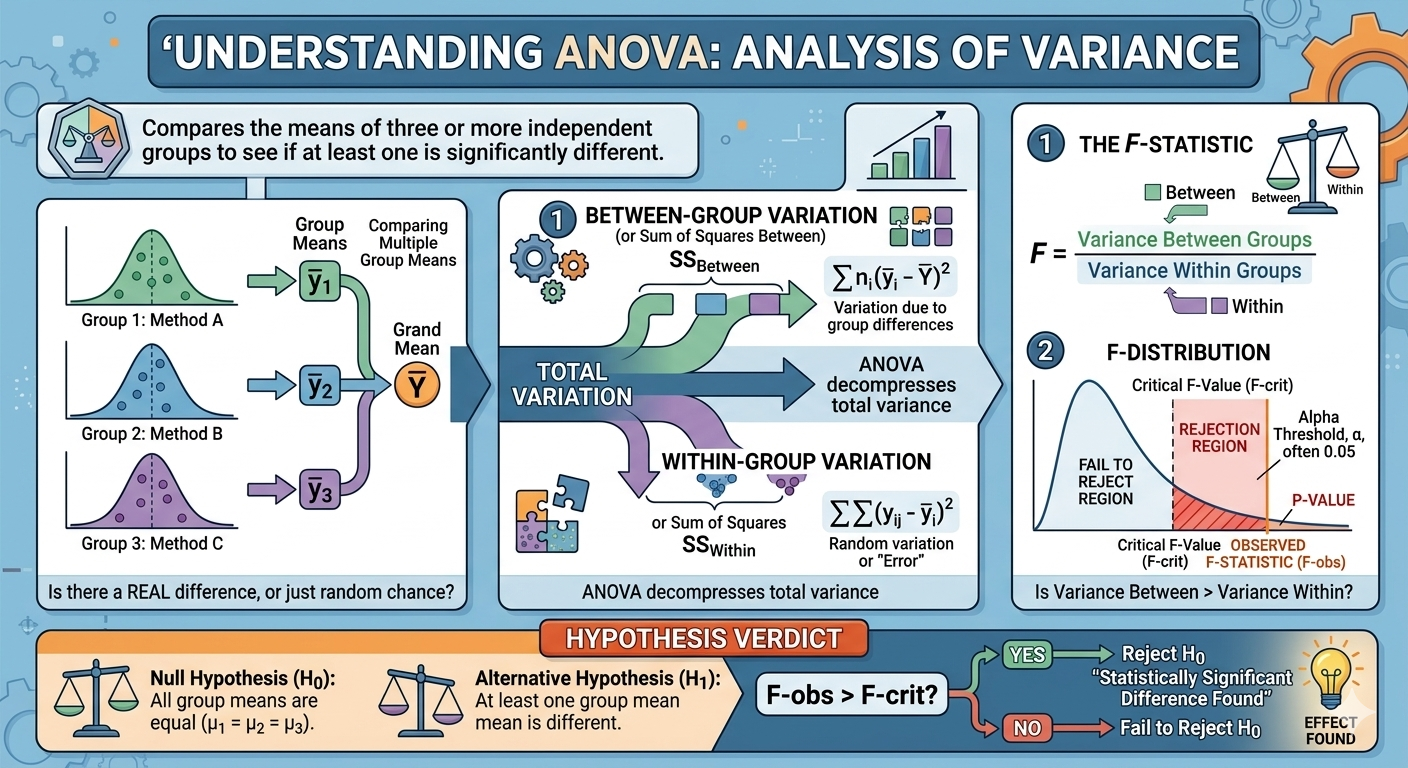


In [98]:
# ! pip install pingouin

In [ ]:
# TODO: compute `df`
# Hint: pd.read_feather
# Name your result: df

In [100]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2261 entries, 0 to 2260
Data columns (total 63 columns):
 #   Column                             Non-Null Count  Dtype   
---  ------                             --------------  -----   
 0   respondent                         2261 non-null   float64 
 1   main_branch                        2261 non-null   object  
 2   hobbyist                           2261 non-null   object  
 3   age                                2261 non-null   float64 
 4   age_1st_code                       2261 non-null   float64 
 5   age_first_code_cut                 2261 non-null   object  
 6   comp_freq                          2261 non-null   object  
 7   comp_total                         2261 non-null   float64 
 8   converted_comp                     2261 non-null   float64 
 9   country                            2261 non-null   object  
 10  currency_desc                      2261 non-null   object  
 11  currency_symbol                    2261 non

In [101]:
df.columns

Index(['respondent', 'main_branch', 'hobbyist', 'age', 'age_1st_code',
       'age_first_code_cut', 'comp_freq', 'comp_total', 'converted_comp',
       'country', 'currency_desc', 'currency_symbol',
       'database_desire_next_year', 'database_worked_with', 'dev_type',
       'ed_level', 'employment', 'ethnicity', 'gender', 'job_factors',
       'job_sat', 'job_seek', 'language_desire_next_year',
       'language_worked_with', 'misc_tech_desire_next_year',
       'misc_tech_worked_with', 'new_collab_tools_desire_next_year',
       'new_collab_tools_worked_with', 'new_dev_ops', 'new_dev_ops_impt',
       'new_ed_impt', 'new_job_hunt', 'new_job_hunt_research', 'new_learn',
       'new_off_topic', 'new_onboard_good', 'new_other_comms', 'new_overtime',
       'new_purchase_research', 'purple_link', 'newso_sites', 'new_stuck',
       'op_sys', 'org_size', 'platform_desire_next_year',
       'platform_worked_with', 'purchase_what', 'sexuality', 'so_account',
       'so_comm', 'so_part_freq'

In [ ]:
# ═══ CHECKPOINT — "Is mean annual compensation different for different levels o" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
from scipy import stats
mu_true = 5.2
mu_0 = 5.0
sigma = 2.0
n = 50
alpha = 0.05
sample = np.random.normal(loc=mu_true, scale=sigma, size=n)
xbar = sample.mean()
se = sigma / np.sqrt(n)
z = (xbar - mu_0) / se
p = 2 * stats.norm.sf(abs(z))
from statsmodels.stats.weightstats import ztest
z_stat, p_val = ztest(sample, value=mu_0)
t_stat, p_val_t = stats.ttest_1samp(sample, popmean=mu_0)
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
import pandas as pd
tips = pd.read_csv('../../00-data/tips.csv')
sample = tips['tip']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sw_stat, sw_p = stats.shapiro(sample)
mu0 = 2.5
res1 = stats.ttest_1samp(sample, popmean=mu0)
ci1 = res1.confidence_interval()
dd0f = n - 1
lunch = tips.loc[tips['time'] == 'Lunch', 'tip']
dinner = tips.loc[tips['time'] == 'Dinner', 'tip']
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
sw_lunch = stats.shapiro(lunch)
sw_dinner = stats.shapiro(dinner)
res2 = stats.ttest_ind(lunch, dinner, equal_var=False)
ci2 = res2.confidence_interval()
sample_df = tips.sample(50, random_state=12)
group_a = sample_df[sample_df['sex'] == 'Male']['tip']
group_b = sample_df[sample_df['sex'] == 'Female']['tip']
stat, p_levene = stats.levene(group_a, group_b)
r1 = stats.ttest_1samp(sample_df['tip'], popmean=3.0)
ci_r1 = r1.confidence_interval()
male_tip_avg = tips[tips['sex'] == 'Male']['tip'].mean()
female_tip_avg = tips[tips['sex'] == 'Female']['tip'].mean()
r2 = stats.ttest_ind(group_a, group_b, equal_var=False)
df = pd.read_csv('../../00-data/taxis.csv')
data = df[['fare', 'tip', 'distance', 'payment', 'pickup_borough']].dropna()
r3 = stats.ttest_1samp(data['fare'], popmean=15.0)
def sig_check(p_value, alpha=0.05):
    print(f'{p_value:.2f}')
    print(f'{alpha}')
    if p_value <= alpha:
        print('Reject H0')
    else:
        print('Fail to reject H0')
credit_tips = data[data['payment'] == 'credit card']['tip']
cash_tips = data[data['payment'] == 'cash']['tip']
for grp in ['credit card', 'cash']:
    resr = data[data['payment'] == grp]['tip']
    stat, p = stats.shapiro(resr)
    print(f'{grp} ,stat:{stat}, p_value:{p}')
t_stat, p_val = stats.ttest_ind(credit_tips, cash_tips, equal_var=False)
import pandas as pd
df = pd.read_csv('../../00-data/sleep.csv')
wide = df.pivot(index='ID', columns='group', values='extra')
wide.columns = ['drug1', 'drug2']
wide['difference'] = wide['drug1'] - wide['drug2']
H0: mean(difference) = 0
H1: mean(difference) != 0
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
sleep = stats.ttest_rel(wide['drug2'], wide['drug1'])
df = pd.read_feather('../../00-data/stack_overflow.feather')

print("Checkpoint restored. Ready for: Is mean annual compensation different for different levels o")

### "Is mean annual compensation different for different levels of education level"

In [102]:
df['converted_comp'].describe()

count    2.261000e+03
mean     1.195747e+05
std      2.655561e+05
min      0.000000e+00
25%      2.749200e+04
50%      5.837300e+04
75%      1.042080e+05
max      2.000000e+06
Name: converted_comp, dtype: float64

In [ ]:
# TODO: draw a boxplot of `converted_comp`, split by `ed_level`
# Hint: sns.boxplot, plt.legend, plt.show

In [104]:
# FIXED: this import was commented out, which killed every
# pingouin cell in the ANOVA section below.
import pingouin as pg

In [ ]:
# TODO: write the code for this step

In [106]:
anova_df = df[['converted_comp','ed_level']].copy()

In [107]:
anova_df = anova_df.dropna()

In [108]:
anova_df.shape

(2246, 2)

In [109]:
top_groups = anova_df['ed_level'].value_counts().head(4).index

In [110]:
anova_top_df = anova_df[anova_df['ed_level'].isin(top_groups)]

In [111]:
anova_top_df.groupby('ed_level')['converted_comp'].agg(
    ['count','mean','median','std','min','max']
)

,count,mean,median,std,min,max
ed_level,,,,,,
"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",743,124061.982503,46891.0,322190.062484,0.0,2000000.0
"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",961,106729.924037,58373.0,210077.664684,0.0,2000000.0
"Other doctoral degree (Ph.D., Ed.D., etc.)",346,139038.855491,77556.0,224152.198062,2349.0,2000000.0
Some college/university study without earning a degree,125,115903.904000,50928.0,284179.760190,2304.0,2000000.0


In [ ]:
# TODO: draw a boxplot of `converted_comp`, split by `ed_level`
# Hint: sns.boxplot, plt.legend, plt.show

In [113]:
q1 = anova_df['converted_comp'].quantile(0.25)
q3 = anova_df['converted_comp'].quantile(0.75)
iqr = q3-q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
anova_top_clean = anova_top_df[
(anova_top_df['converted_comp']>=lower)&
(anova_top_df['converted_comp']<=upper)].copy()

In [ ]:
# TODO: draw a boxplot of `converted_comp`, split by `ed_level`
# Hint: sns.boxplot, plt.legend, plt.show

In [115]:
groups = [group['converted_comp'].values for name,group in anova_top_clean.groupby('ed_level')]
groups

[array([3.78160e+04, 1.30000e+05, 8.50000e+04, 1.65000e+05, 4.18800e+03,
        2.37350e+04, 1.37271e+05, 4.28040e+04, 1.45440e+04, 8.35000e+04,
        2.32800e+03, 1.70000e+05, 1.70000e+05, 1.50000e+05, 1.68000e+05,
        3.00000e+04, 2.00000e+05, 9.10000e+04, 2.20000e+05, 8.20000e+04,
        5.25600e+03, 1.80000e+05, 7.50000e+04, 1.17000e+05, 1.30000e+05,
        1.55000e+05, 6.70000e+04, 7.35480e+04, 4.00320e+04, 1.88000e+05,
        2.33640e+04, 1.04710e+04, 1.03408e+05, 8.00000e+04, 5.19970e+04,
        1.39000e+05, 4.89240e+04, 8.00000e+04, 7.60000e+04, 1.35000e+05,
        1.20000e+05, 2.00000e+05, 1.86000e+05, 8.50000e+04, 1.35000e+05,
        8.30000e+04, 4.12320e+04, 1.60000e+05, 8.70000e+04, 8.00000e+04,
        1.97000e+05, 5.90000e+04, 9.00000e+04, 3.93280e+04, 4.91190e+04,
        7.80720e+04, 1.09179e+05, 8.47950e+04, 1.45000e+05, 1.20000e+05,
        1.05000e+05, 5.83730e+04, 1.05000e+05, 1.20000e+05, 1.00000e+05,
        5.81240e+04, 5.50000e+04, 1.50000e+05, 8.50

In [116]:
group_names = list(anova_top_clean.groupby('ed_level').groups.keys())

In [ ]:
# TODO: write the code for this step

In [ ]:
# TODO: run a one-way ANOVA
# Hint: stats.f_oneway

In [119]:
p_val,f_stat

(np.float64(4.152959650242471e-18), np.float64(28.59914854772461))

In [120]:
sig_check(p_val)

0.00
0.05
Reject H0


In [ ]:
# TODO: run an ANOVA on `converted_comp` across `ed_level`, storing the result in `result`
# Hint: pg.anova
# Name your result: result

In [122]:
result

,Source,ddof1,ddof2,F,p_unc,np2
0,ed_level,3,2023,28.599149,4.152960e-18,0.040685


In [123]:
anova_top_clean.shape

(2027, 2)

In [124]:
4-1,

(3,)

In [125]:
sig_check(result.p_unc[0])

0.00
0.05
Reject H0


In [126]:
df

,respondent,main_branch,hobbyist,age,age_1st_code,age_first_code_cut,comp_freq,comp_total,converted_comp,country,...,survey_length,trans,undergrad_major,webframe_desire_next_year,webframe_worked_with,welcome_change,work_week_hrs,years_code,years_code_pro,age_cat
0,36.0,"I am not primarily a developer, but I write co...",Yes,34.0,30.0,adult,Yearly,60000.0,77556.0,United Kingdom,...,Appropriate in length,No,"Computer science, computer engineering, or sof...",Express;React.js,Express;React.js,Just as welcome now as I felt last year,40.0,4.0,3.0,At least 30
1,47.0,I am a developer by profession,Yes,53.0,10.0,child,Yearly,58000.0,74970.0,United Kingdom,...,Appropriate in length,No,"A natural science (such as biology, chemistry,...",Flask;Spring,Flask;Spring,Just as welcome now as I felt last year,40.0,43.0,28.0,At least 30
2,69.0,I am a developer by profession,Yes,25.0,12.0,child,Yearly,550000.0,594539.0,France,...,Too short,No,"Computer science, computer engineering, or sof...",Django;Flask,Django;Flask,Just as welcome now as I felt last year,40.0,13.0,3.0,Under 30
3,125.0,"I am not primarily a developer, but I write co...",Yes,41.0,30.0,adult,Monthly,200000.0,2000000.0,United States,...,Appropriate in length,No,None,None,None,Just as welcome now as I felt last year,40.0,11.0,11.0,At least 30
4,147.0,"I am not primarily a developer, but I write co...",No,28.0,15.0,adult,Yearly,50000.0,37816.0,Canada,...,Appropriate in length,No,"Another engineering discipline (such as civil,...",None,Express;Flask,Just as welcome now as I felt last year,40.0,5.0,3.0,Under 30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2256,62812.0,I am a developer by profession,Yes,40.0,10.0,child,Yearly,145000.0,145000.0,United States,...,Too long,No,"Computer science, computer engineering, or sof...",Flask;jQuery,Angular;Angular.js;Flask;jQuery;React.js,Somewhat less welcome now than last year,50.0,30.0,20.0,At least 30
2257,62835.0,I am a developer by profession,Yes,23.0,9.0,child,Monthly,180000.0,33972.0,Russian Federation,...,Too short,No,"Computer science, computer engineering, or sof...",ASP.NET Core,ASP.NET Core;Flask,Just as welcome now as I felt last year,60.0,8.0,3.0,Under 30
2258,62837.0,I am a developer by profession,Yes,27.0,8.0,child,Monthly,7500.0,97284.0,Germany,...,Appropriate in length,No,Mathematics or statistics,None,None,Just as welcome now as I felt last year,42.0,12.0,2.0,Under 30
2259,62867.0,"I am not primarily a developer, but I write co...",Yes,33.0,13.0,child,Monthly,6000.0,72000.0,Panama,...,Too long,No,"Another engineering discipline (such as civil,...",None,Django;React.js,A lot less welcome now than last year,45.0,15.0,2.0,At least 30


In [127]:
# anova_df.plot(kind='hist',edgecolor='black')

In [128]:
# anova_top_clean.plot(kind='hist',edgecolor='black')

create a copy of df
dropna
clean the outlier and save it as pg_df
pg.anova()

In [129]:
df2 = df.copy()

> **A note on what happens next.** The cell below removes outliers with an IQR fence so
> the ANOVA assumptions hold. That is a defensible teaching shortcut, but be clear about
> the cost: **you are no longer testing the population you started with** — you have
> deleted the highest earners, who are exactly the people a compensation study cares about.
>
> For income, revenue, and any other right-skewed money variable, the standard move is to
> **log-transform instead of trim**:
>
> ```python
> pg_df['log_comp'] = np.log1p(df2['converted_comp'])
> ```
>
> This pulls the tail in, usually satisfies the assumptions, and keeps every row. The
> trade-off is that your results are then about *proportional* differences rather than
> dollar differences. Try both and compare the conclusions.

In [ ]:
# TODO: compute `df2`, `q1`, `q3`
# Hint: df2.dropna, .quantile(), .copy()
# Name your result: df2, q1, q3, iqr

In [131]:
pg_df = robust_clean(df2,'converted_comp')

Column: converted_comp: 25 outliers removed


In [ ]:
# ═══ CHECKPOINT — "Things to do before ANOVA" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
from scipy import stats
mu_true = 5.2
mu_0 = 5.0
sigma = 2.0
n = 50
alpha = 0.05
sample = np.random.normal(loc=mu_true, scale=sigma, size=n)
xbar = sample.mean()
se = sigma / np.sqrt(n)
z = (xbar - mu_0) / se
p = 2 * stats.norm.sf(abs(z))
from statsmodels.stats.weightstats import ztest
z_stat, p_val = ztest(sample, value=mu_0)
t_stat, p_val_t = stats.ttest_1samp(sample, popmean=mu_0)
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
import pandas as pd
tips = pd.read_csv('../../00-data/tips.csv')
sample = tips['tip']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sw_stat, sw_p = stats.shapiro(sample)
mu0 = 2.5
res1 = stats.ttest_1samp(sample, popmean=mu0)
ci1 = res1.confidence_interval()
dd0f = n - 1
lunch = tips.loc[tips['time'] == 'Lunch', 'tip']
dinner = tips.loc[tips['time'] == 'Dinner', 'tip']
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
sw_lunch = stats.shapiro(lunch)
sw_dinner = stats.shapiro(dinner)
res2 = stats.ttest_ind(lunch, dinner, equal_var=False)
ci2 = res2.confidence_interval()
sample_df = tips.sample(50, random_state=12)
group_a = sample_df[sample_df['sex'] == 'Male']['tip']
group_b = sample_df[sample_df['sex'] == 'Female']['tip']
stat, p_levene = stats.levene(group_a, group_b)
r1 = stats.ttest_1samp(sample_df['tip'], popmean=3.0)
ci_r1 = r1.confidence_interval()
male_tip_avg = tips[tips['sex'] == 'Male']['tip'].mean()
female_tip_avg = tips[tips['sex'] == 'Female']['tip'].mean()
r2 = stats.ttest_ind(group_a, group_b, equal_var=False)
df = pd.read_csv('../../00-data/taxis.csv')
data = df[['fare', 'tip', 'distance', 'payment', 'pickup_borough']].dropna()
r3 = stats.ttest_1samp(data['fare'], popmean=15.0)
def sig_check(p_value, alpha=0.05):
    print(f'{p_value:.2f}')
    print(f'{alpha}')
    if p_value <= alpha:
        print('Reject H0')
    else:
        print('Fail to reject H0')
credit_tips = data[data['payment'] == 'credit card']['tip']
cash_tips = data[data['payment'] == 'cash']['tip']
for grp in ['credit card', 'cash']:
    resr = data[data['payment'] == grp]['tip']
    stat, p = stats.shapiro(resr)
    print(f'{grp} ,stat:{stat}, p_value:{p}')
t_stat, p_val = stats.ttest_ind(credit_tips, cash_tips, equal_var=False)
import pandas as pd
df = pd.read_csv('../../00-data/sleep.csv')
wide = df.pivot(index='ID', columns='group', values='extra')
wide.columns = ['drug1', 'drug2']
wide['difference'] = wide['drug1'] - wide['drug2']
H0: mean(difference) = 0
H1: mean(difference) != 0
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
sleep = stats.ttest_rel(wide['drug2'], wide['drug1'])
df = pd.read_feather('../../00-data/stack_overflow.feather')
import pingouin as pg
anova_df = df[['converted_comp', 'ed_level']].copy()
anova_df = anova_df.dropna()
top_groups = anova_df['ed_level'].value_counts().head(4).index
anova_top_df = anova_df[anova_df['ed_level'].isin(top_groups)]
q1 = anova_df['converted_comp'].quantile(0.25)
q3 = anova_df['converted_comp'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
anova_top_clean = anova_top_df[(anova_top_df['converted_comp'] >= lower) & (anova_top_df['converted_comp'] <= upper)].copy()
groups = [group['converted_comp'].values for name, group in anova_top_clean.groupby('ed_level')]
group_names = list(anova_top_clean.groupby('ed_level').groups.keys())
f_stat, p_val = stats.f_oneway(*groups)
result = pg.anova(data=anova_top_clean, dv='converted_comp', between='ed_level')
df2 = df.copy()
df2 = df2.dropna()
def robust_clean(df, column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df_clean = df[(df[column] >= lower) & (df[column] <= upper)].copy()
    removed = len(df) - len(df_clean)
    print(f'Column: {column}: {removed} outliers removed')
    return df_clean
pg_df = robust_clean(df2, 'converted_comp')

print("Checkpoint restored. Ready for: Things to do before ANOVA")

## Things to do before ANOVA

In [ ]:
# TODO: call `pg.normality`
# Hint: pg.normality

In [ ]:
# TODO: call `pg.homoscedasticity`
# Hint: pg.homoscedasticity

## ANOVA


In [ ]:
# TODO: run an ANOVA on `converted_comp` across `ed_level`, storing the result in `result`
# Hint: pg.anova
# Name your result: result

In [135]:
sig_check(result['p_unc'][0])

0.09
0.05
Fail to reject H0


In [ ]:
# ═══ CHECKPOINT — "Post test" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
from scipy import stats
mu_true = 5.2
mu_0 = 5.0
sigma = 2.0
n = 50
alpha = 0.05
sample = np.random.normal(loc=mu_true, scale=sigma, size=n)
xbar = sample.mean()
se = sigma / np.sqrt(n)
z = (xbar - mu_0) / se
p = 2 * stats.norm.sf(abs(z))
from statsmodels.stats.weightstats import ztest
z_stat, p_val = ztest(sample, value=mu_0)
t_stat, p_val_t = stats.ttest_1samp(sample, popmean=mu_0)
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
import pandas as pd
tips = pd.read_csv('../../00-data/tips.csv')
sample = tips['tip']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sw_stat, sw_p = stats.shapiro(sample)
mu0 = 2.5
res1 = stats.ttest_1samp(sample, popmean=mu0)
ci1 = res1.confidence_interval()
dd0f = n - 1
lunch = tips.loc[tips['time'] == 'Lunch', 'tip']
dinner = tips.loc[tips['time'] == 'Dinner', 'tip']
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
sw_lunch = stats.shapiro(lunch)
sw_dinner = stats.shapiro(dinner)
res2 = stats.ttest_ind(lunch, dinner, equal_var=False)
ci2 = res2.confidence_interval()
sample_df = tips.sample(50, random_state=12)
group_a = sample_df[sample_df['sex'] == 'Male']['tip']
group_b = sample_df[sample_df['sex'] == 'Female']['tip']
stat, p_levene = stats.levene(group_a, group_b)
r1 = stats.ttest_1samp(sample_df['tip'], popmean=3.0)
ci_r1 = r1.confidence_interval()
male_tip_avg = tips[tips['sex'] == 'Male']['tip'].mean()
female_tip_avg = tips[tips['sex'] == 'Female']['tip'].mean()
r2 = stats.ttest_ind(group_a, group_b, equal_var=False)
df = pd.read_csv('../../00-data/taxis.csv')
data = df[['fare', 'tip', 'distance', 'payment', 'pickup_borough']].dropna()
r3 = stats.ttest_1samp(data['fare'], popmean=15.0)
def sig_check(p_value, alpha=0.05):
    print(f'{p_value:.2f}')
    print(f'{alpha}')
    if p_value <= alpha:
        print('Reject H0')
    else:
        print('Fail to reject H0')
credit_tips = data[data['payment'] == 'credit card']['tip']
cash_tips = data[data['payment'] == 'cash']['tip']
for grp in ['credit card', 'cash']:
    resr = data[data['payment'] == grp]['tip']
    stat, p = stats.shapiro(resr)
    print(f'{grp} ,stat:{stat}, p_value:{p}')
t_stat, p_val = stats.ttest_ind(credit_tips, cash_tips, equal_var=False)
import pandas as pd
df = pd.read_csv('../../00-data/sleep.csv')
wide = df.pivot(index='ID', columns='group', values='extra')
wide.columns = ['drug1', 'drug2']
wide['difference'] = wide['drug1'] - wide['drug2']
H0: mean(difference) = 0
H1: mean(difference) != 0
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
sleep = stats.ttest_rel(wide['drug2'], wide['drug1'])
df = pd.read_feather('../../00-data/stack_overflow.feather')
import pingouin as pg
anova_df = df[['converted_comp', 'ed_level']].copy()
anova_df = anova_df.dropna()
top_groups = anova_df['ed_level'].value_counts().head(4).index
anova_top_df = anova_df[anova_df['ed_level'].isin(top_groups)]
q1 = anova_df['converted_comp'].quantile(0.25)
q3 = anova_df['converted_comp'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
anova_top_clean = anova_top_df[(anova_top_df['converted_comp'] >= lower) & (anova_top_df['converted_comp'] <= upper)].copy()
groups = [group['converted_comp'].values for name, group in anova_top_clean.groupby('ed_level')]
group_names = list(anova_top_clean.groupby('ed_level').groups.keys())
f_stat, p_val = stats.f_oneway(*groups)
result = pg.anova(data=anova_top_clean, dv='converted_comp', between='ed_level')
df2 = df.copy()
df2 = df2.dropna()
def robust_clean(df, column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df_clean = df[(df[column] >= lower) & (df[column] <= upper)].copy()
    removed = len(df) - len(df_clean)
    print(f'Column: {column}: {removed} outliers removed')
    return df_clean
pg_df = robust_clean(df2, 'converted_comp')
result = pg.anova(pg_df, dv='converted_comp', between='ed_level')

print("Checkpoint restored. Ready for: Post test")

### Post test

In [ ]:
# TODO: call `pg.pairwise_tukey`
# Hint: pg.pairwise_tukey

p_tukey < 0.05 -> 2 groups compared are sig diff
p_tukey > 0.05 -> 2 groups compared are not sig diff


In [ ]:
# TODO: call `pg.pairwise_gameshowell`
# Hint: pg.pairwise_gameshowell

## Report an effect size, not just a p-value

The ANOVA table above prints `np2` — partial eta-squared — and the original notebook
never mentioned it. At this sample size that is the column that carries the information.

`np2` is **the share of variance in compensation that education level explains**:

| `np2` | Reading |
|---|---|
| ≈ 0.01 | small — detectable, probably not actionable |
| ≈ 0.06 | medium |
| ≥ 0.14 | large |

Run the cell below and compare the two numbers. The p-value tells you the difference is
*detectable*; `np2` tells you how much of what you care about it actually accounts for.
This is the distinction that matters once your datasets get large, because at large *n*
the p-value stops discriminating at all.

In [ ]:
# TODO: run an ANOVA on `converted_comp` across `ed_level`, storing the result in `result`
# Hint: pg.anova, .to_string(), .dropna()
# Name your result: result, eta, size

p_value < 0.05 -> 2 groups compared are sig diff
p_value > 0.05 -> 2 groups compared are not sig diff

In [139]:
df.columns

Index(['respondent', 'main_branch', 'hobbyist', 'age', 'age_1st_code',
       'age_first_code_cut', 'comp_freq', 'comp_total', 'converted_comp',
       'country', 'currency_desc', 'currency_symbol',
       'database_desire_next_year', 'database_worked_with', 'dev_type',
       'ed_level', 'employment', 'ethnicity', 'gender', 'job_factors',
       'job_sat', 'job_seek', 'language_desire_next_year',
       'language_worked_with', 'misc_tech_desire_next_year',
       'misc_tech_worked_with', 'new_collab_tools_desire_next_year',
       'new_collab_tools_worked_with', 'new_dev_ops', 'new_dev_ops_impt',
       'new_ed_impt', 'new_job_hunt', 'new_job_hunt_research', 'new_learn',
       'new_off_topic', 'new_onboard_good', 'new_other_comms', 'new_overtime',
       'new_purchase_research', 'purple_link', 'newso_sites', 'new_stuck',
       'op_sys', 'org_size', 'platform_desire_next_year',
       'platform_worked_with', 'purchase_what', 'sexuality', 'so_account',
       'so_comm', 'so_part_freq'

In [ ]:
# ═══ CHECKPOINT — "Exercise:" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import numpy as np
from scipy import stats
mu_true = 5.2
mu_0 = 5.0
sigma = 2.0
n = 50
alpha = 0.05
sample = np.random.normal(loc=mu_true, scale=sigma, size=n)
xbar = sample.mean()
se = sigma / np.sqrt(n)
z = (xbar - mu_0) / se
p = 2 * stats.norm.sf(abs(z))
from statsmodels.stats.weightstats import ztest
z_stat, p_val = ztest(sample, value=mu_0)
t_stat, p_val_t = stats.ttest_1samp(sample, popmean=mu_0)
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt
import pandas as pd
tips = pd.read_csv('../../00-data/tips.csv')
sample = tips['tip']
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sw_stat, sw_p = stats.shapiro(sample)
mu0 = 2.5
res1 = stats.ttest_1samp(sample, popmean=mu0)
ci1 = res1.confidence_interval()
dd0f = n - 1
lunch = tips.loc[tips['time'] == 'Lunch', 'tip']
dinner = tips.loc[tips['time'] == 'Dinner', 'tip']
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
sw_lunch = stats.shapiro(lunch)
sw_dinner = stats.shapiro(dinner)
res2 = stats.ttest_ind(lunch, dinner, equal_var=False)
ci2 = res2.confidence_interval()
sample_df = tips.sample(50, random_state=12)
group_a = sample_df[sample_df['sex'] == 'Male']['tip']
group_b = sample_df[sample_df['sex'] == 'Female']['tip']
stat, p_levene = stats.levene(group_a, group_b)
r1 = stats.ttest_1samp(sample_df['tip'], popmean=3.0)
ci_r1 = r1.confidence_interval()
male_tip_avg = tips[tips['sex'] == 'Male']['tip'].mean()
female_tip_avg = tips[tips['sex'] == 'Female']['tip'].mean()
r2 = stats.ttest_ind(group_a, group_b, equal_var=False)
df = pd.read_csv('../../00-data/taxis.csv')
data = df[['fare', 'tip', 'distance', 'payment', 'pickup_borough']].dropna()
r3 = stats.ttest_1samp(data['fare'], popmean=15.0)
def sig_check(p_value, alpha=0.05):
    print(f'{p_value:.2f}')
    print(f'{alpha}')
    if p_value <= alpha:
        print('Reject H0')
    else:
        print('Fail to reject H0')
credit_tips = data[data['payment'] == 'credit card']['tip']
cash_tips = data[data['payment'] == 'cash']['tip']
for grp in ['credit card', 'cash']:
    resr = data[data['payment'] == grp]['tip']
    stat, p = stats.shapiro(resr)
    print(f'{grp} ,stat:{stat}, p_value:{p}')
t_stat, p_val = stats.ttest_ind(credit_tips, cash_tips, equal_var=False)
import pandas as pd
df = pd.read_csv('../../00-data/sleep.csv')
wide = df.pivot(index='ID', columns='group', values='extra')
wide.columns = ['drug1', 'drug2']
wide['difference'] = wide['drug1'] - wide['drug2']
H0: mean(difference) = 0
H1: mean(difference) != 0
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
sleep = stats.ttest_rel(wide['drug2'], wide['drug1'])
df = pd.read_feather('../../00-data/stack_overflow.feather')
import pingouin as pg
anova_df = df[['converted_comp', 'ed_level']].copy()
anova_df = anova_df.dropna()
top_groups = anova_df['ed_level'].value_counts().head(4).index
anova_top_df = anova_df[anova_df['ed_level'].isin(top_groups)]
q1 = anova_df['converted_comp'].quantile(0.25)
q3 = anova_df['converted_comp'].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
anova_top_clean = anova_top_df[(anova_top_df['converted_comp'] >= lower) & (anova_top_df['converted_comp'] <= upper)].copy()
groups = [group['converted_comp'].values for name, group in anova_top_clean.groupby('ed_level')]
group_names = list(anova_top_clean.groupby('ed_level').groups.keys())
f_stat, p_val = stats.f_oneway(*groups)
result = pg.anova(data=anova_top_clean, dv='converted_comp', between='ed_level')
df2 = df.copy()
df2 = df2.dropna()
def robust_clean(df, column):
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    df_clean = df[(df[column] >= lower) & (df[column] <= upper)].copy()
    removed = len(df) - len(df_clean)
    print(f'Column: {column}: {removed} outliers removed')
    return df_clean
pg_df = robust_clean(df2, 'converted_comp')
result = pg.anova(pg_df, dv='converted_comp', between='ed_level')
result = pg.anova(pg_df, dv='converted_comp', between='ed_level', detailed=True)
eta = result['np2'].dropna().iloc[0]
size = 'large' if eta >= 0.14 else 'medium' if eta >= 0.06 else 'small'

print("Checkpoint restored. Ready for: Exercise:")

### Exercise:

### "Is mean annual compensation different for different levels of job_sat"

---

# How this is used in data science and machine learning

### 1. A/B testing is this notebook with money attached
Two-sample tests are how a product change gets shipped or shelved. The pipeline in this
notebook — state H₀, fix α, check variances with Levene, run Welch, report the interval —
is the pipeline an experimentation platform runs for you.

### 2. Paired tests are how you compare two models honestly
Comparing model A and model B across the same *k* cross-validation folds is a **paired**
design: the same data, two treatments. Using an independent t-test there throws away the
pairing and loses power, exactly as it would in the sleep-drug data above.

### 3. The p-value is not the finding. The effect size is.
This is the single most important carry-over, and the place most practitioners go wrong.

A p-value depends on **effect size and sample size together**. In machine learning you are
usually working with tens of thousands of rows, so:

> at large *n*, everything is statistically significant, including differences far too
> small to act on.

The exam dataset in this module makes the point at 10,000 rows: every p-value comes back
as `0.000`. The only informative numbers left are the effect sizes. So always report both:

| Effect size | Used for | Rough reading |
|---|---|---|
| **Cohen's d** / **Hedges' g** | difference between two means | 0.2 small · 0.5 medium · 0.8 large |
| **η²ₚ** (partial eta-squared) | ANOVA factors | 0.01 small · 0.06 medium · 0.14 large |
| **r** / **ρ** | association | square it for shared variance |

"Significant" answers *did we detect something*. Effect size answers *is it worth doing
anything about* — and only the second one is a business decision.

### 4. ANOVA's F-statistic is a feature selection filter
`sklearn.feature_selection.f_classif` — the default scorer for `SelectKBest` on a
classification problem — **runs a one-way ANOVA on every feature**, treating the target
classes as groups. A high F means that feature's values separate the classes relative to
the noise within them. When you call `SelectKBest(f_classif, k=20)`, you are running the
test from the end of this notebook twenty thousand times.

### 5. Multiple comparisons is why feature screening lies to you
Test 100 useless features at α = 0.05 and roughly **5 of them will look significant by
construction**. This is the same problem Tukey and Bonferroni solve in this notebook, and
it is why:
- a "significant" feature found by scanning hundreds of candidates needs validating on
  held-out data,
- and "we tried 40 model variants and this one beat the baseline" is not evidence.

### 6. Levene's test is a variance check you will reuse
Comparing variances, not just means, is how you detect that two groups differ in
*consistency* — a model that is equally accurate on two segments but far more erratic on
one of them is a fairness and reliability problem that a mean comparison hides entirely.